# Modelado final

In [2]:
import os
os.environ["IB_FAST"] = "1"
os.environ["IB_MAX_ROWS"] = "40000"
os.environ["IB_FINAL_MAX_ROWS"] = "150000"

In [3]:
import os, sys, json, warnings, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import Markdown, display
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score

from src import config, eda, utils
from src import modeling as M

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

FAST = os.environ.get("IB_FAST") == "1"
MAX_ROWS = int(os.environ.get("IB_MAX_ROWS", 0))
N_REPEATS = 1 if FAST else config.N_REPEATS
N_TRIALS = 8 if FAST else config.OPTUNA_TRIALS
RESULTS = {}

def savefig(name):
    plt.savefig(config.FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

print(f"FAST={FAST} | repeticiones={N_REPEATS} | trials Optuna={N_TRIALS}")

FAST=True | repeticiones=1 | trials Optuna=8


## 1. Dataset consolidado

In [4]:
SOURCES = tuple(s for s in ("rcc", "sunat", "se", "censo") if (config.PROC_DIR / f"features_{s}_train.parquet").exists())
print("Fuentes disponibles en data/processed:", SOURCES)
if len(SOURCES) < 4:
    print("AVISO: faltan fuentes", sorted(set(("rcc", "sunat", "se", "censo")) - set(SOURCES)),
          "→ ejecuta antes los notebooks 01–04 / scripts 01–04 para el modelo completo.")
data = M.load_dataset(SOURCES, load_test=False, max_rows=MAX_ROWS)
X_all, y, y_full = data["X_train"], data["y"], data["y_full"]
if MAX_ROWS and len(X_all) < len(y_full):
    print(f"IB_MAX_ROWS={MAX_ROWS:,}: la exploración (CV, tuning, holdout) usa una submuestra estratificada; "
          f"el modelo final se reentrena con {min(int(os.environ.get('IB_FINAL_MAX_ROWS', 0)) or len(y_full), len(y_full)):,} clientes de train")
tk = data["submission_template"][M.KEY].sample(min(100_000, len(data["submission_template"])), random_state=config.SEED)
X_test = M.load_split("test", SOURCES, keys=pd.Index(tk))

groups = pd.Series([M.feature_source(c) for c in X_all.columns]).value_counts().rename("variables").to_frame()
display(groups.T)
print(f"Train (exploración): {X_all.shape[0]:,} de {len(y_full):,} clientes × {X_all.shape[1]} variables  |  muestra de test para diagnósticos: {X_test.shape[0]:,} clientes")
print(f"Tasa de default: {y.mean():.2%}  ({int(y.sum()):,} defaults)")

cov = pd.DataFrame({"train": X_all.filter(regex="_tiene_(historial|registro)$").mean(),
                    "test": X_test.filter(regex="_tiene_(historial|registro)$").mean()}).mul(100).round(1)
cov.index = [i.replace("_tiene_historial", "").replace("_tiene_registro", "") for i in cov.index]
cov.rename_axis("fuente (% de clientes con información)")

Fuentes disponibles en data/processed: ('rcc', 'sunat', 'se', 'censo')


00:36:13 | INFO | Dataset: train (40000, 459) | tasa de default 15.82%


IB_MAX_ROWS=40,000: la exploración (CV, tuning, holdout) usa una submuestra estratificada; el modelo final se reentrena con 150,000 clientes de train


,rcc,censo,sunat,se,otras
variables,174,154,115,15,1


Train (exploración): 40,000 de 358,487 clientes × 459 variables  |  muestra de test para diagnósticos: 100,000 clientes
Tasa de default: 15.82%  (6,328 defaults)


,train,test
fuente (% de clientes con información),,
rcc,88.6,89.3
sunat,65.6,64.0
se,100.0,100.0
censo,43.0,50.6


## 2. Limpieza sin target

In [5]:
keep, pruned = M.unsupervised_prune(X_all, X_test)
print(f"Variables antes: {X_all.shape[1]} → después: {len(keep)}  ({len(pruned)} eliminadas)")
display(pruned.groupby("motivo", as_index=False).size().assign(motivo=lambda d: d.motivo.str.split(" con ").str[0]).groupby("motivo", as_index=False)["size"].sum())
X_all, X_test = X_all[keep], X_test[keep]

Variables antes: 459 → después: 373  (86 eliminadas)


,motivo,size
0,casi_vacia,8
1,constante,13
2,corr>0.98,65


## 3. Desfase entre cohortes: validación adversarial y PSI

AUC adversarial (todas las variables): 0.864


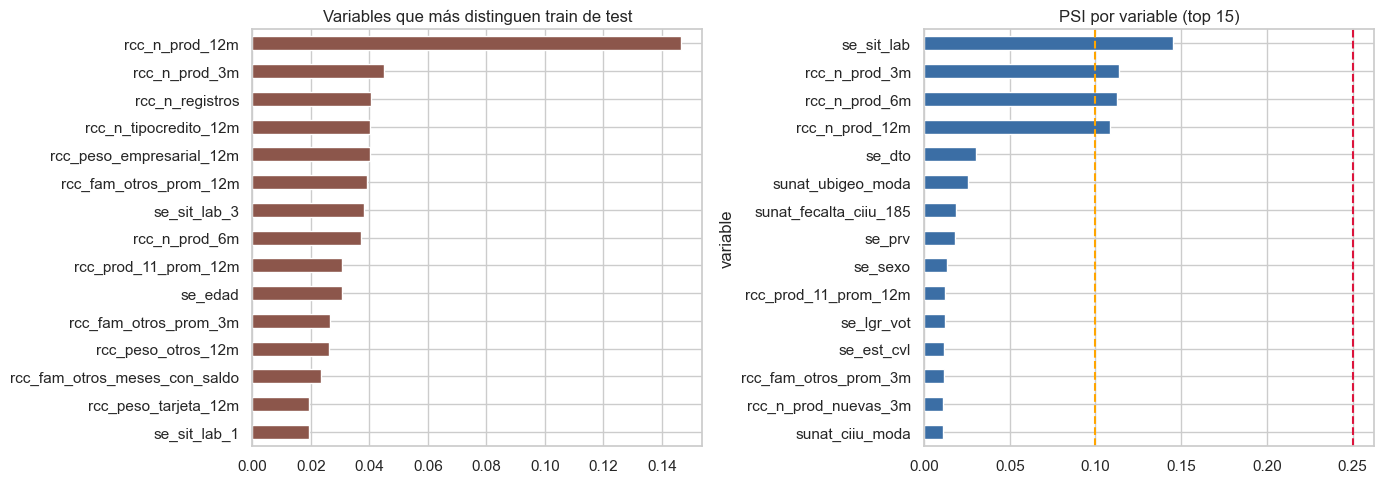

Variables con PSI > 0.25: 0  ·  entre 0.10 y 0.25: 4


In [6]:
adv = M.adversarial_validation(X_all, X_test)
psi_t = M.psi_table(X_all, X_test)
RESULTS["adv_auc_inicial"] = adv["auc"]
print(f"AUC adversarial (todas las variables): {adv['auc']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
adv["importance"].head(15)[::-1].plot.barh(ax=ax[0], color="#8c564b")
ax[0].set_title("Variables que más distinguen train de test")
psi_t.head(15).set_index("variable")["psi"][::-1].plot.barh(ax=ax[1], color="#3b6ea5")
ax[1].axvline(0.10, ls="--", c="orange"); ax[1].axvline(0.25, ls="--", c="crimson")
ax[1].set_title("PSI por variable (top 15)")
plt.tight_layout(); savefig("drift_inicial"); plt.show()
print(f"Variables con PSI > 0.25: {(psi_t.psi > 0.25).sum()}  ·  entre 0.10 y 0.25: {psi_t.psi.between(0.10, 0.25).sum()}")

In [7]:
keep_drift, hist = M.drift_prune(X_all, X_test, threshold=0.65, initial=adv)
display(hist)
removed = [c for c in X_all.columns if c not in keep_drift]
print(f"Variables eliminadas por drift: {len(removed)}", removed[:20])
RESULTS["adv_auc_final"] = float(hist.auc_adversarial.iloc[-1])
RESULTS["n_drift_removed"] = len(removed)
X_all, X_test = X_all[keep_drift], X_test[keep_drift]
print(f"Variables finales para modelar: {X_all.shape[1]}")

,iteracion,auc_adversarial,n_variables
0,0,0.864203,373
1,1,0.845090,370
2,2,0.699641,367
3,3,0.673726,364
4,4,0.656192,361
5,5,0.642871,358


Variables eliminadas por drift: 15 ['rcc_n_registros', 'rcc_n_prod_3m', 'rcc_n_prod_6m', 'rcc_n_prod_12m', 'rcc_n_prod_nuevas_3m', 'rcc_inst_34_prom_3m', 'rcc_inst_34_prom_12m', 'rcc_fam_otros_prom_3m', 'rcc_fam_otros_prom_6m', 'rcc_fam_otros_prom_12m', 'rcc_fam_otros_meses_con_saldo', 'rcc_peso_otros_12m', 'rcc_prod_11_prom_12m', 'se_edad', 'se_sit_lab']
Variables finales para modelar: 358


## 4. Partición y validación

In [8]:
X_dev, X_ho, y_dev, y_ho = M.holdout_split(X_all, y)
print(f"dev: {len(y_dev):,} (default {y_dev.mean():.2%})  |  holdout: {len(y_ho):,} (default {y_ho.mean():.2%})")

if len(X_dev) > 150_000:
    N_REPEATS = 1
    print(f"Base grande ({len(X_dev):,} filas en dev): se usa 1 repetición de CV")
t0 = time.time()
PF_TREE = M.PreparedFolds(X_dev, y_dev, "tree", n_repeats=N_REPEATS)
PF_LIN = M.PreparedFolds(X_dev, y_dev, "linear", n_repeats=N_REPEATS)
print(f"{len(PF_TREE.folds)} folds preparados en {time.time() - t0:.0f}s · variables tras preprocesar: {len(PF_TREE.folds[0]['cols'])}")

dev: 32,000 (default 15.82%)  |  holdout: 8,000 (default 15.82%)
5 folds preparados en 21s · variables tras preprocesar: 410


## 5. Modelos base

In [9]:
def summarize(name, res):
    a = res["auc_folds"]
    return dict(modelo=name, auc_cv=a.mean(), desv=a.std(), min=a.min(), max=a.max(),
                auc_oof=roc_auc_score(y_dev, res["oof"]))

cands, rows = {}, []
for C in (0.01, 0.05, 0.2):
    cands[f"LogReg C={C}"] = PF_LIN.evaluate(M.make_logreg(C)); rows.append(summarize(f"LogReg C={C}", cands[f"LogReg C={C}"]))
cands["RandomForest"] = PF_TREE.evaluate(M.make_rf()); rows.append(summarize("RandomForest", cands["RandomForest"]))
cands["LightGBM base"] = PF_TREE.evaluate(M.make_lgbm()); rows.append(summarize("LightGBM base", cands["LightGBM base"]))

baseline = pd.DataFrame(rows).set_index("modelo").round(4)
display(baseline)
best_lr_name = baseline.filter(like="LogReg", axis=0).auc_cv.idxmax()
BEST_C = float(best_lr_name.split("=")[1])
print("Mejor regularización logística:", best_lr_name)

,auc_cv,desv,min,max,auc_oof
modelo,,,,,
LogReg C=0.01,0.8194,0.0058,0.8123,0.8267,0.8194
LogReg C=0.05,0.8188,0.0057,0.8125,0.8259,0.8188
LogReg C=0.2,0.8183,0.0059,0.8120,0.8254,0.8183
RandomForest,0.8162,0.0051,0.8063,0.8203,0.8160
LightGBM base,0.8335,0.0060,0.8243,0.8408,0.8334


Mejor regularización logística: LogReg C=0.01


### ¿Ayuda reducir variables?

In [10]:
sel_rows = []
for k in ((60, None) if FAST else (30, 60, 100, None)):
    r = PF_TREE.evaluate(M.make_lgbm(), top_k=k)
    sel_rows.append(dict(variables=k or "todas", auc_cv=r["auc_folds"].mean(), desv=r["auc_folds"].std()))
sel = pd.DataFrame(sel_rows).set_index("variables").round(4)
display(sel)
RESULTS["seleccion"] = sel.auc_cv.to_dict()

,auc_cv,desv
variables,,
60,0.8313,0.0064
todas,0.8335,0.0060


## 6. Tuning de LightGBM (Optuna, TPE)

00:54:58 | INFO | Optuna: mejor AUC CV 0.8328 en 8 trials


Tuning sobre 32,000 filas: 267s · mejor AUC (1 repetición): 0.8328


,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha,min_split_gain,scale_pos_weight
valor,292.0,0.045975,18.0,6.0,118.0,0.673942,0.878709,7.365344,5.727904,0.447414,1.781373


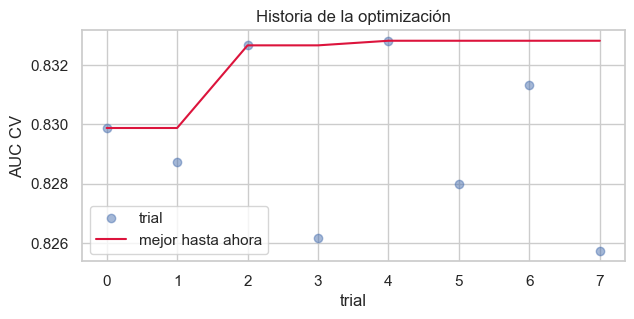

In [11]:
t0 = time.time()
X_tune, y_tune = M.stratified_sample(X_dev, y_dev, 50_000 if FAST else 100_000)
PF_TUNE = PF_TREE if len(X_tune) == len(X_dev) else M.PreparedFolds(X_tune, y_tune, "tree", n_repeats=1)
tuned = M.tune_lgbm(PF_TUNE, n_trials=N_TRIALS)
BEST = tuned["params"]
(config.REPORTS_DIR / "best_params.json").write_text(json.dumps(BEST, indent=2))
print(f"Tuning sobre {len(X_tune):,} filas: {time.time() - t0:.0f}s · mejor AUC (1 repetición): {tuned['best_value']:.4f}")
display(pd.Series(BEST, name="valor").to_frame().T)

study = tuned["study"]
vals = [t.value for t in study.trials]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(vals, "o", alpha=.5, label="trial"); ax.plot(np.maximum.accumulate(vals), c="crimson", label="mejor hasta ahora")
ax.set_xlabel("trial"); ax.set_ylabel("AUC CV"); ax.legend(); ax.set_title("Historia de la optimización")
savefig("optuna_history"); plt.show()

imp = pd.Series(study.best_trial.params).rename("valor")

,auc_cv,desv,min,max,auc_oof
modelo,,,,,
LightGBM base,0.8335,0.0060,0.8243,0.8408,0.8334
LightGBM tuned,0.8328,0.0060,0.8246,0.8399,0.8327
LogReg C=0.01,0.8194,0.0058,0.8123,0.8267,0.8194
LogReg C=0.05,0.8188,0.0057,0.8125,0.8259,0.8188
LogReg C=0.2,0.8183,0.0059,0.8120,0.8254,0.8183
RandomForest,0.8162,0.0051,0.8063,0.8203,0.8160


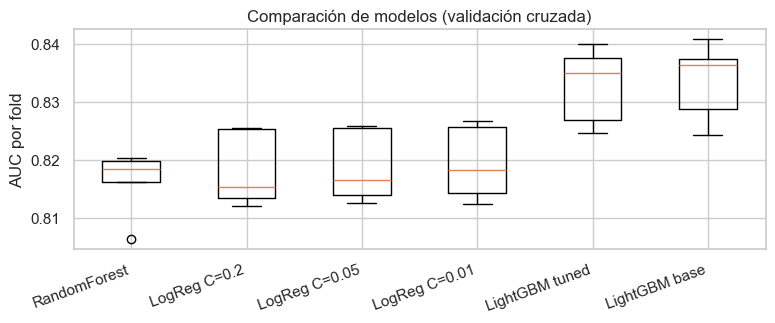

In [12]:
cands["LightGBM tuned"] = PF_TREE.evaluate(M.make_lgbm(**BEST))
rows.append(summarize("LightGBM tuned", cands["LightGBM tuned"]))
comp = pd.DataFrame(rows).set_index("modelo").round(4)
display(comp.sort_values("auc_cv", ascending=False))

fig, ax = plt.subplots(figsize=(8, 3.4))
order = comp.sort_values("auc_cv").index
ax.boxplot([cands[m]["auc_folds"] for m in order])
ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_ylabel("AUC por fold"); ax.set_title("Comparación de modelos (validación cruzada)")
plt.tight_layout(); savefig("comparacion_modelos"); plt.show()

## 7. Blend LightGBM + regresión logística

Peso elegido para LightGBM: 0.8  (AUC OOF 0.8339; solo LightGBM 0.8327; solo logística 0.8194)


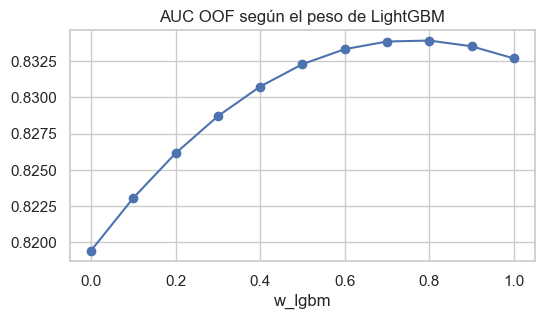

In [13]:
oof_lgb = cands["LightGBM tuned"]["oof_by_rep"]
oof_lr = cands[best_lr_name]["oof_by_rep"]
stats = M.blend_stats(oof_lgb.mean(0), oof_lr.mean(0))

grid = []
for w in np.round(np.linspace(0, 1, 11), 1):
    aucs = [roc_auc_score(y_dev, M.blend_scores(oof_lgb[r], oof_lr[r], w, stats)) for r in range(N_REPEATS)]
    grid.append(dict(w_lgbm=w, auc_oof=np.mean(aucs)))
grid = pd.DataFrame(grid).set_index("w_lgbm")
W = float(grid.auc_oof.idxmax())
print(f"Peso elegido para LightGBM: {W}  (AUC OOF {grid.auc_oof.max():.4f}; solo LightGBM {grid.loc[1.0, 'auc_oof']:.4f}; solo logística {grid.loc[0.0, 'auc_oof']:.4f})")
grid.auc_oof.plot(marker="o", figsize=(6, 3), title="AUC OOF según el peso de LightGBM"); plt.xlabel("w_lgbm"); savefig("blend_peso"); plt.show()

oof_blend = M.blend_scores(oof_lgb.mean(0), oof_lr.mean(0), W, stats)
RESULTS["cv"] = {"logreg": float(cands[best_lr_name]["auc_folds"].mean()),
                 "rf": float(cands["RandomForest"]["auc_folds"].mean()),
                 "lgbm_base": float(cands["LightGBM base"]["auc_folds"].mean()),
                 "lgbm_tuned": float(cands["LightGBM tuned"]["auc_folds"].mean()),
                 "lgbm_tuned_std": float(cands["LightGBM tuned"]["auc_folds"].std()),
                 "blend_oof": float(roc_auc_score(y_dev, oof_blend)), "w_lgbm": W}

In [14]:
import gc
for _n in ("PF_TREE", "PF_LIN", "PF_TUNE"):
    _pf = globals().pop(_n, None)
    if _pf is not None:
        _pf.close()
gc.collect()

7435

## 8. Evaluación en el holdout (datos nunca vistos)

In [15]:
t0 = time.time()
ho = M.fit_final(X_dev, y_dev, X_ho, BEST, logreg_C=BEST_C, n_seeds=3)
s_blend_ho = M.blend_scores(ho["p_lgbm"], ho["p_logreg"], W, stats)
print(f"Ajuste y predicción: {time.time() - t0:.0f}s")

rows = []
for name, s in (("Regresión logística", ho["p_logreg"]), ("LightGBM", ho["p_lgbm"]), ("Blend", s_blend_ho)):
    m = utils.summarize_metrics(y_ho, np.clip(s, 0, 1) if name != "Blend" else 1 / (1 + np.exp(-s)))
    lo, hi = M.bootstrap_ci(y_ho, s)
    rows.append(dict(modelo=name, auc=m["auc"], ic95_inf=lo, ic95_sup=hi, gini=m["gini"], ks=m["ks"], pr_auc=m["pr_auc"]))
holdout = pd.DataFrame(rows).set_index("modelo").round(4)
display(holdout)
RESULTS["holdout"] = holdout.to_dict("index")
print(f"AUC del holdout (blend): {holdout.loc['Blend','auc']:.4f}  [IC95 {holdout.loc['Blend','ic95_inf']:.4f} – {holdout.loc['Blend','ic95_sup']:.4f}]")

Ajuste y predicción: 20s


,auc,ic95_inf,ic95_sup,gini,ks,pr_auc
modelo,,,,,,
Regresión logística,0.8172,0.8032,0.8303,0.6345,0.4764,0.5848
LightGBM,0.8382,0.8251,0.8498,0.6764,0.5028,0.6192
Blend,0.8379,0.8245,0.8494,0.6758,0.5024,0.6187


AUC del holdout (blend): 0.8379  [IC95 0.8245 – 0.8494]


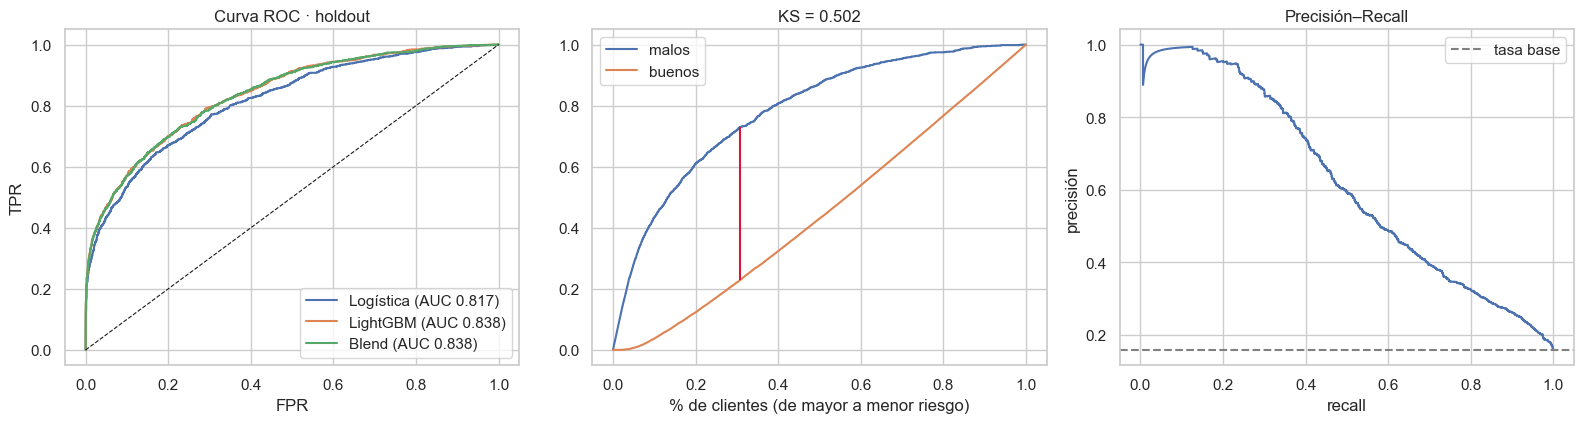

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for name, s in (("Logística", ho["p_logreg"]), ("LightGBM", ho["p_lgbm"]), ("Blend", s_blend_ho)):
    fpr, tpr, _ = roc_curve(y_ho, s)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_ho, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("Curva ROC · holdout"); ax[0].legend(); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")

d = pd.DataFrame({"y": y_ho.values, "s": s_blend_ho}).sort_values("s", ascending=False)
cum_bad = (d.y.cumsum() / d.y.sum()).values; cum_good = ((1 - d.y).cumsum() / (1 - d.y).sum()).values
x = np.arange(1, len(d) + 1) / len(d)
ax[1].plot(x, cum_bad, label="malos"); ax[1].plot(x, cum_good, label="buenos")
k = np.argmax(cum_bad - cum_good); ax[1].vlines(x[k], cum_good[k], cum_bad[k], color="crimson")
ax[1].set_title(f"KS = {cum_bad[k] - cum_good[k]:.3f}"); ax[1].set_xlabel("% de clientes (de mayor a menor riesgo)"); ax[1].legend()

pr, rc, _ = precision_recall_curve(y_ho, s_blend_ho)
ax[2].plot(rc, pr); ax[2].axhline(y_ho.mean(), ls="--", c="gray", label="tasa base")
ax[2].set_title("Precisión–Recall"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precisión"); ax[2].legend()
plt.tight_layout(); savefig("evaluacion_holdout"); plt.show()

### Tabla de deciles y lift

,decil,clientes,defaults,tasa_default,score_medio,lift,captura_acum
0,1,800,550,0.688,2.105,4.344,0.434
1,2,800,222,0.278,0.812,1.754,0.610
2,3,800,138,0.172,0.444,1.090,0.719
3,4,800,112,0.140,0.209,0.885,0.807
4,5,800,82,0.102,0.016,0.648,0.872
5,6,800,67,0.084,-0.178,0.529,0.925
6,7,800,36,0.045,-0.390,0.284,0.953
7,8,800,27,0.034,-0.615,0.213,0.975
8,9,800,25,0.031,-0.870,0.197,0.994
9,10,800,7,0.009,-1.379,0.055,1.000


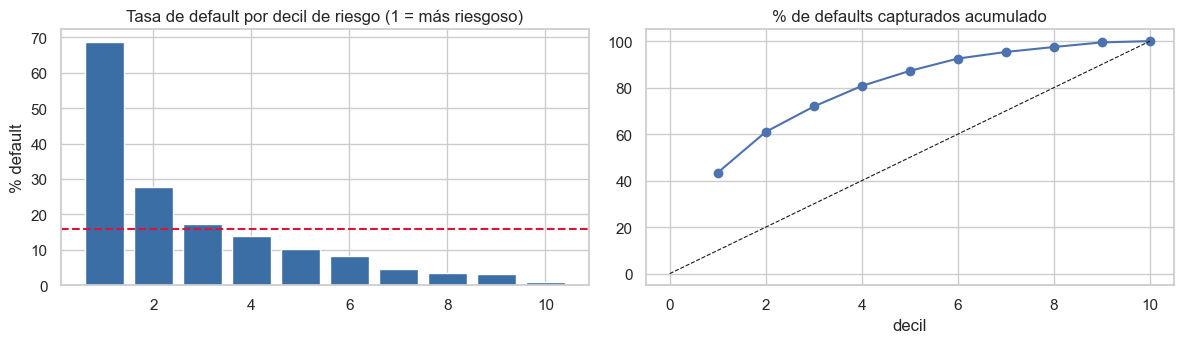

In [17]:
dec = utils.decile_table(y_ho, s_blend_ho)
display(dec.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(dec.decil.astype(int), dec.tasa_default * 100, color="#3b6ea5"); ax[0].axhline(y_ho.mean() * 100, ls="--", c="crimson")
ax[0].set_title("Tasa de default por decil de riesgo (1 = más riesgoso)"); ax[0].set_ylabel("% default")
ax[1].plot(dec.decil.astype(int), dec.captura_acum * 100, "o-"); ax[1].plot([0, 10], [0, 100], "k--", lw=.8)
ax[1].set_title("% de defaults capturados acumulado"); ax[1].set_xlabel("decil")
plt.tight_layout(); savefig("deciles"); plt.show()
RESULTS["lift_decil1"] = float(dec.lift.iloc[0]); RESULTS["captura_30"] = float(dec.captura_acum.iloc[2])

## 9. Calibración

,brier,ece,prob_media
version,,,
LightGBM sin calibrar,0.0954,0.0538,0.2121
Blend calibrado (Platt),0.0912,0.0063,0.1582


Tasa real de default en el holdout: 0.1583  ·  AUC antes/después de calibrar: 0.8379 / 0.8379


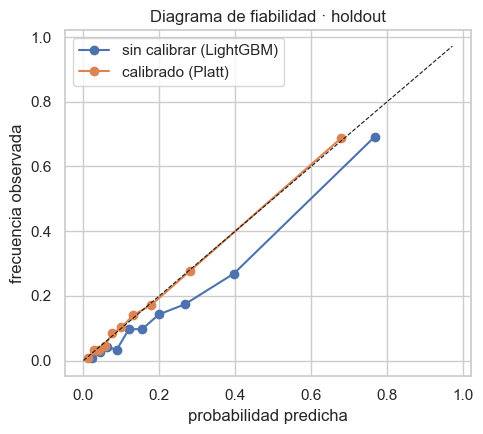

In [18]:
sig = lambda z: 1 / (1 + np.exp(-z))
cal = M.PlattCalibrator().fit(sig(oof_blend), y_dev.values)
p_cal_ho = cal.predict(sig(s_blend_ho))

rows = [dict(version="LightGBM sin calibrar", brier=utils.summarize_metrics(y_ho, ho["p_lgbm"])["brier"], ece=M.expected_calibration_error(y_ho.values, ho["p_lgbm"]), prob_media=ho["p_lgbm"].mean()),
        dict(version="Blend calibrado (Platt)", brier=utils.summarize_metrics(y_ho, p_cal_ho)["brier"], ece=M.expected_calibration_error(y_ho.values, p_cal_ho), prob_media=p_cal_ho.mean())]
display(pd.DataFrame(rows).set_index("version").round(4))
print(f"Tasa real de default en el holdout: {y_ho.mean():.4f}  ·  AUC antes/después de calibrar: {roc_auc_score(y_ho, s_blend_ho):.4f} / {roc_auc_score(y_ho, p_cal_ho):.4f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
for name, p in (("sin calibrar (LightGBM)", ho["p_lgbm"]), ("calibrado (Platt)", p_cal_ho)):
    df = pd.DataFrame({"y": y_ho.values, "p": p}); df["b"] = pd.qcut(df.p.rank(method="first"), 10, labels=False)
    g = df.groupby("b").agg(p=("p", "mean"), y=("y", "mean")); ax.plot(g.p, g.y, "o-", label=name)
lim = max(0.01, float(np.quantile(ho["p_lgbm"], .99)))
ax.plot([0, lim], [0, lim], "k--", lw=.8); ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("frecuencia observada")
ax.set_title("Diagrama de fiabilidad · holdout"); ax.legend(); plt.tight_layout(); savefig("calibracion"); plt.show()
RESULTS["calibracion"] = {"ece_antes": rows[0]["ece"], "ece_despues": rows[1]["ece"]}

## 10. Punto de corte y decisión de negocio

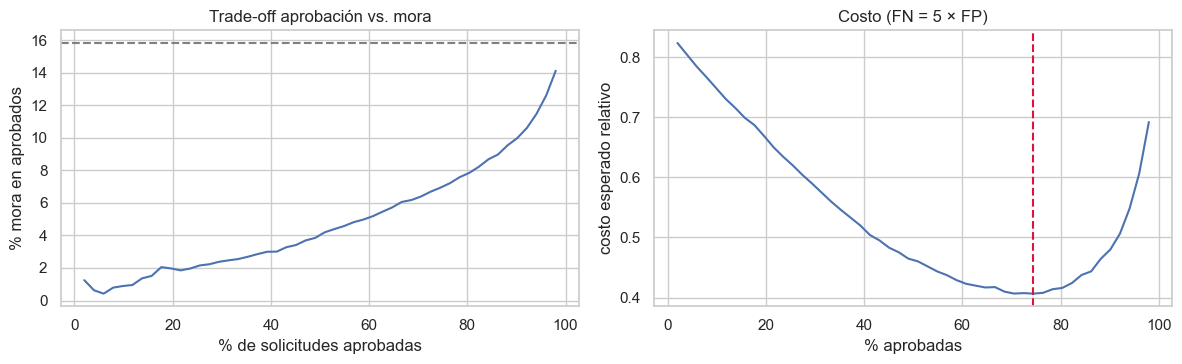

,aprobacion,corte,mora_aprobados,malos_aprobados,buenos_rechazados
0,0.6078,0.1166,0.0518,252.0,2124.0
1,0.7058,0.1539,0.0639,361.0,1449.0
2,0.8036,0.2187,0.0784,504.0,809.0
3,0.9016,0.3820,0.0998,720.0,241.0


Corte de mínimo costo: probabilidad ≤ 0.1737 → aprueba 74%, mora de aprobados 6.93% (base 15.82%)


In [19]:
tt = M.threshold_table(y_ho, p_cal_ho)
best = tt.loc[tt.costo.idxmin()]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(tt.aprobacion * 100, tt.mora_aprobados * 100); ax[0].axhline(y_ho.mean() * 100, ls="--", c="gray")
ax[0].set_xlabel("% de solicitudes aprobadas"); ax[0].set_ylabel("% mora en aprobados"); ax[0].set_title("Trade-off aprobación vs. mora")
ax[1].plot(tt.aprobacion * 100, tt.costo); ax[1].axvline(best.aprobacion * 100, c="crimson", ls="--")
ax[1].set_xlabel("% aprobadas"); ax[1].set_ylabel("costo esperado relativo"); ax[1].set_title(f"Costo (FN = {config.COST_FN_OVER_FP:g} × FP)")
plt.tight_layout(); savefig("punto_de_corte"); plt.show()

pick = [tt.iloc[(tt.aprobacion - a).abs().argmin()] for a in (0.6, 0.7, 0.8, 0.9)]
display(pd.DataFrame(pick)[["aprobacion", "corte", "mora_aprobados", "malos_aprobados", "buenos_rechazados"]].round(4).reset_index(drop=True))
print(f"Corte de mínimo costo: probabilidad ≤ {best.corte:.4f} → aprueba {best.aprobacion:.0%}, mora de aprobados {best.mora_aprobados:.2%} (base {y_ho.mean():.2%})")

In [20]:
import gc; gc.collect()
(config.REPORTS_DIR / "metrics_parcial.json").write_text(json.dumps(RESULTS, indent=2, default=float))

1121

## 11. Interpretabilidad

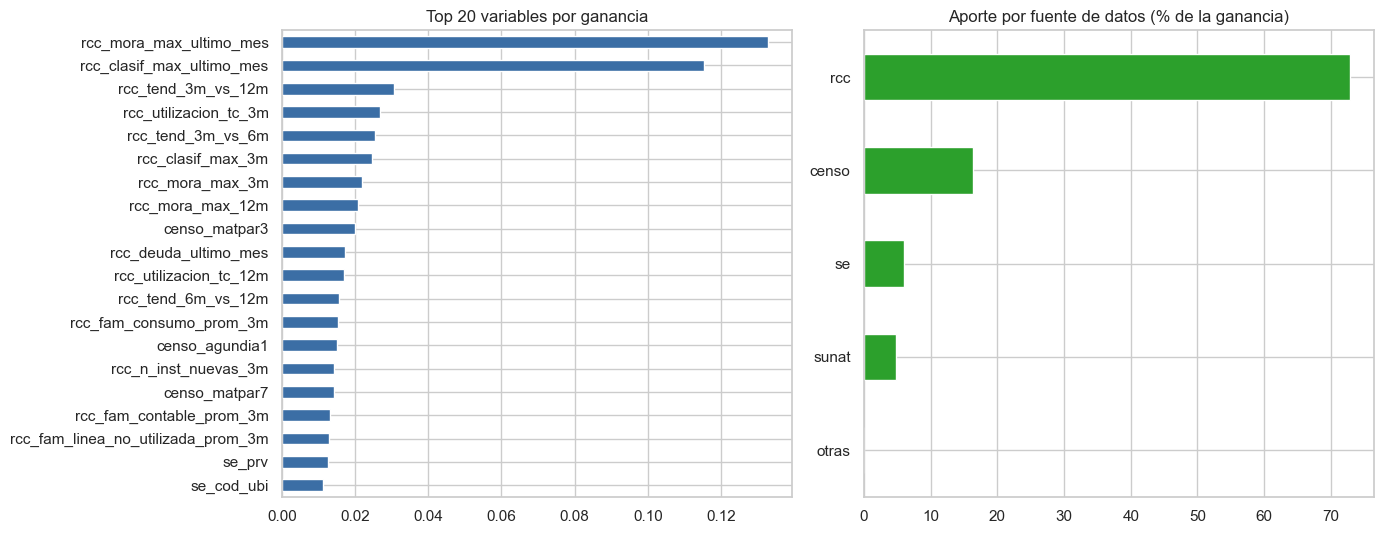

In [21]:
pt = M.Prep("tree")
Xd = pt.fit_transform(X_dev, y_dev)
X_shap = X_ho.sample(min(5000, len(X_ho)), random_state=config.SEED)
Xh = pt.transform(X_shap)
m1 = M.make_lgbm(**BEST, importance_type="gain").fit(Xd, y_dev)
gain = pd.Series(m1.feature_importances_, index=Xd.columns).sort_values(ascending=False)
gain = gain / gain.sum()

by_src = gain.groupby([M.feature_source(c) for c in gain.index]).sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
gain.head(20)[::-1].plot.barh(ax=ax[0], color="#3b6ea5"); ax[0].set_title("Top 20 variables por ganancia")
by_src[::-1].mul(100).plot.barh(ax=ax[1], color="#2ca02c"); ax[1].set_title("Aporte por fuente de datos (% de la ganancia)")
plt.tight_layout(); savefig("importancia"); plt.show()
RESULTS["aporte_fuente"] = by_src.round(4).to_dict()
RESULTS["top_variables"] = gain.head(10).round(4).to_dict()

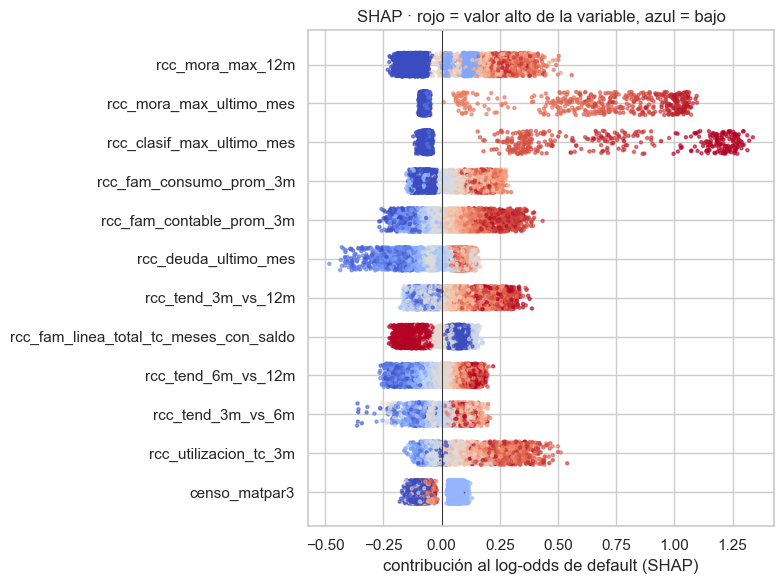

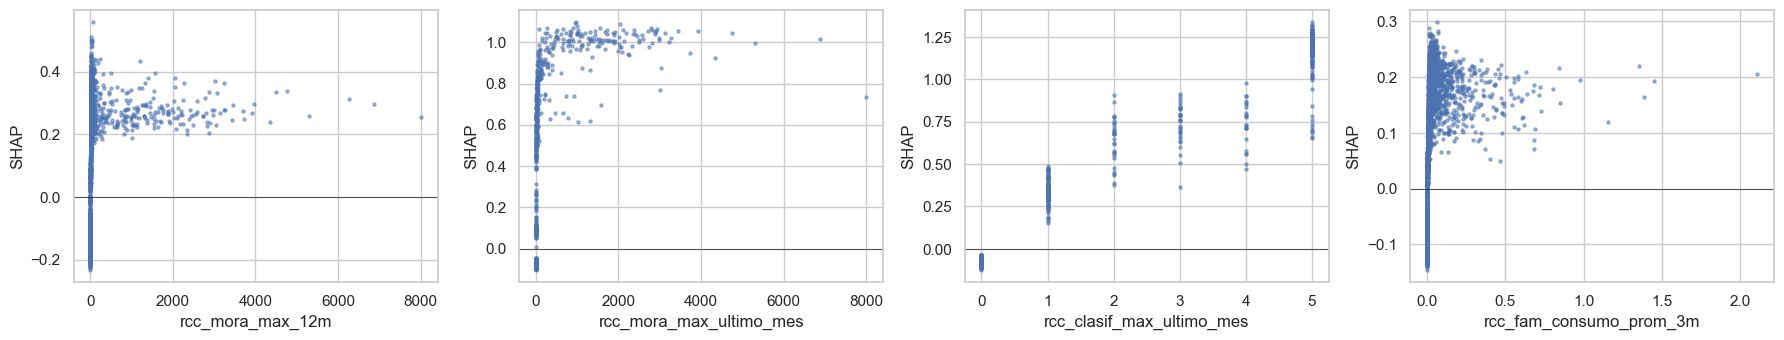

In [22]:
sv = M.lgbm_contributions(m1, Xh)
order = sv.abs().mean().sort_values(ascending=False).index[:12]
fig, ax = plt.subplots(figsize=(8, 6))
for i, c in enumerate(order[::-1]):
    v = Xh[c].rank(pct=True).fillna(0.5)
    ax.scatter(sv[c], np.full(len(sv), i) + np.random.default_rng(0).uniform(-.3, .3, len(sv)), c=v, cmap="coolwarm", s=5, alpha=.6)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order[::-1]); ax.axvline(0, c="k", lw=.6)
ax.set_xlabel("contribución al log-odds de default (SHAP)"); ax.set_title("SHAP · rojo = valor alto de la variable, azul = bajo")
plt.tight_layout(); savefig("shap_resumen"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, c in zip(axes, order[:4]):
    ax.scatter(Xh[c], sv[c], s=5, alpha=.5); ax.set_xlabel(c); ax.set_ylabel("SHAP"); ax.axhline(0, c="k", lw=.5)
plt.tight_layout(); savefig("shap_dependencia"); plt.show()

## 12. Estabilidad y desempeño por segmento

In [23]:
rep_auc = [roc_auc_score(y_dev, oof_lgb[r]) for r in range(N_REPEATS)]
print("AUC OOF de LightGBM por repetición:", np.round(rep_auc, 4))

hist_col = "rcc_tiene_historial"
if hist_col in X_ho.columns:
    seg = []
    for lab, mask in (("con historial RCC", X_ho[hist_col] == 1), ("sin historial RCC", X_ho[hist_col] == 0)):
        yy = y_ho[mask.values]
        seg.append(dict(segmento=lab, clientes=int(mask.sum()), tasa_default=yy.mean() if len(yy) else np.nan,
                        auc=roc_auc_score(yy, s_blend_ho[mask.values]) if yy.nunique() == 2 and len(yy) > 30 else np.nan))
    display(pd.DataFrame(seg).set_index("segmento").round(4))

AUC OOF de LightGBM por repetición: [0.8327]


,clientes,tasa_default,auc
segmento,,,
con historial RCC,7157,0.1619,0.8476
sin historial RCC,843,0.1269,0.7221


## 13. Modelo final y predicción sobre la cohorte 2019

00:55:54 | INFO | Reentrenando con 150,000 clientes de train (de 358,487): (150000, 358)
00:59:46 | INFO | Listo: 396666 filas en C:\Users\Xavi\Downloads\ESTUDIO_AUTODIDACTA\Proyectos CV\Proyectos Git Hub\modelo-credit-scoring\reports\submission.csv

Reentrenamiento con 150,000 de 358,487 clientes de train y predicción sobre test: 239s
Probabilidad media predicha en test: 0.1566  ·  tasa de default en train: 0.1582
PSI del score (OOF 2018 vs test 2019): 0.002


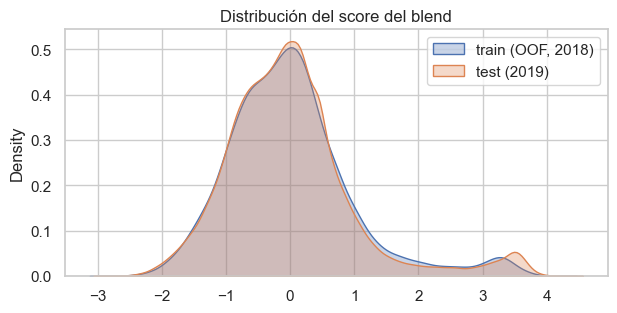

,key_value,target
0,0,0.006126
1,1,0.144383
2,2,0.032046
3,3,0.421071
4,4,0.451172


In [24]:
import gc, subprocess
FEATURES = list(X_all.columns)
joblib.dump({"features": FEATURES, "sources": list(SOURCES), "params": BEST, "logreg_C": BEST_C, "n_seeds": 5,
             "w_lgbm": W, "blend_stats": stats, "calibrator": cal}, config.MODELS_DIR / "final_config.joblib")
del X_all, X_dev, X_ho; gc.collect()
t0 = time.time()
res = subprocess.run([sys.executable, "-m", "src.final_stage"], cwd=ROOT, capture_output=True, text=True)
print(res.stdout[-600:] + res.stderr[-1500:] if res.returncode else res.stderr[-400:])
res.check_returncode()
pr = np.load(config.MODELS_DIR / "predictions_test.npz")
s_test, p_test = pr["s_test"], pr["p_test"]
sub = pd.read_csv(config.REPORTS_DIR / "submission.csv")
n_final = min(int(os.environ.get("IB_FINAL_MAX_ROWS", 0)) or len(y_full), len(y_full))
print(f"Reentrenamiento con {n_final:,} de {len(y_full):,} clientes de train y predicción sobre test: {time.time() - t0:.0f}s")

psi_score = utils.psi(oof_blend, s_test)
print(f"Probabilidad media predicha en test: {p_test.mean():.4f}  ·  tasa de default en train: {y.mean():.4f}")
print(f"PSI del score (OOF 2018 vs test 2019): {psi_score:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.kdeplot(oof_blend, ax=ax, label="train (OOF, 2018)", fill=True, alpha=.3); sns.kdeplot(s_test, ax=ax, label="test (2019)", fill=True, alpha=.3)
ax.set_title("Distribución del score del blend"); ax.legend(); savefig("score_train_vs_test"); plt.show()
RESULTS["psi_score"] = psi_score; RESULTS["p_media_test"] = float(p_test.mean())
sub.head()

## Resultados

In [25]:
h = RESULTS["holdout"]["Blend"]
cv = RESULTS["cv"]
resumen = f"""
| Evaluación | AUC |
|---|---|
| Regresión logística (CV) | {cv['logreg']:.4f} |
| Random Forest (CV) | {cv['rf']:.4f} |
| LightGBM base (CV) | {cv['lgbm_base']:.4f} |
| LightGBM tuneado (CV) | {cv['lgbm_tuned']:.4f} ± {cv['lgbm_tuned_std']:.4f} |
| Blend en OOF | {cv['blend_oof']:.4f} |
| **Blend en holdout** | **{h['auc']:.4f}** (IC 95 %: {h['ic95_inf']:.4f} – {h['ic95_sup']:.4f}) |

KS {h['ks']:.3f} · Gini {h['gini']:.3f} · PR-AUC {h['pr_auc']:.3f} · lift decil 1 {RESULTS['lift_decil1']:.1f}x · ECE {RESULTS['calibracion']['ece_despues']:.4f} · PSI del score {RESULTS['psi_score']:.3f}
"""
display(Markdown(resumen))
(config.REPORTS_DIR / "metrics.json").write_text(json.dumps(RESULTS, indent=2, default=float))


| Evaluación | AUC |
|---|---|
| Regresión logística (CV) | 0.8194 |
| Random Forest (CV) | 0.8162 |
| LightGBM base (CV) | 0.8335 |
| LightGBM tuneado (CV) | 0.8328 ± 0.0060 |
| Blend en OOF | 0.8339 |
| **Blend en holdout** | **0.8379** (IC 95 %: 0.8245 – 0.8494) |

KS 0.502 · Gini 0.676 · PR-AUC 0.619 · lift decil 1 4.3x · ECE 0.0063 · PSI del score 0.002


1692